Here we show the superiority of underdamped Langevin sampling for RNNs observing a univariate Ornstein-Uhlenbeck process, where the optimal update $\Delta r_1(t) = \frac{d}{d r(t)} \log p(r(t))$ is given.

Explanatory figure 1: univariate case, sigma=1. This shows how underdamped dynamics can help _accelerate_ sampling

Experiment for appendix: univariate case, WD vs $\sigma_r$ for 1st-order, 2nd-order w/ $\lambda$, and adaptation w/ $\tau_a$, $b_a$.

In [ ]:
#@title Imports and helper functions
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import sqrtm
from tqdm import tqdm

import torch
from torch import nn
import torch.nn.functional as F

globalsize = 12
legendsize = 10
labelsize = globalsize + 2
plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = globalsize

def wasserstein_distance(m1, m2, C1, C2):
    sqrt_C2 = sqrtm(C2)
    return np.linalg.norm(m1 - m2)**2 + np.trace(C1 + C2 - 2 * sqrtm(sqrt_C2 @ C1 @ sqrt_C2))

def cov(rs):
    return np.mean([np.outer(r_i, r_i) for r_i in rs], axis=0) - \
           np.outer(rs.mean(0), rs.mean(0))

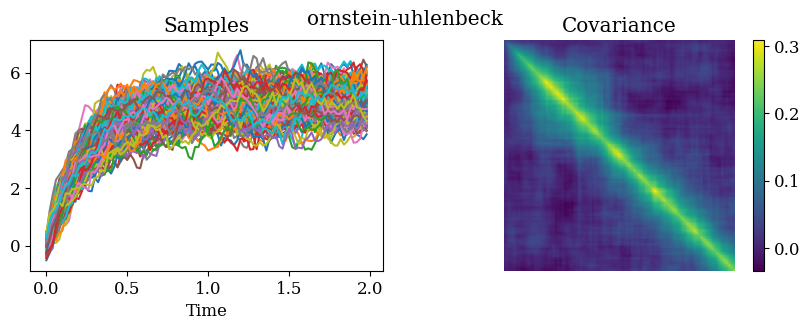

In [ ]:
#@title setup
dt = 0.02
sigma_s = 0.2 # different from previous notebook
sigma_init = 0.2
mu_init, mu = 0, 5
#mu_init, mu = 5, 0 # special settings to observe adaptation's properties
leak = 4 # different from previous notebook
N = 200
T = 100

wiener = False

np.random.seed(0)

if wiener:
    # Wiener process
    s = (np.random.normal(size=(N,T)) * sigma_s).cumsum(axis=1)
else:
    # Ornstein-Uhlenbeck process
    s = np.zeros((N, T))
    s[:,0] = np.random.normal(size=s[:,0].shape) * sigma_init + mu_init
    for t in range(1,T):
        s[:,t] = (1 - leak * dt) * s[:, t-1] + leak * dt * mu + sigma_s * np.random.normal(size=s[:,t].shape)


cov_s = cov(s)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,3))
axs[0].set_title('Samples')
axs[0].plot(np.arange(T) * dt, s.T)
axs[0].set_xlabel('Time')
axs[1].set_title('Covariance')
pos = axs[1].imshow(cov_s)
fig.colorbar(pos, ax=axs[1])
axs[1].axis('off')
fig.suptitle(f'wiener' if wiener else 'ornstein-uhlenbeck')
fig.show()

In [ ]:
#@title langevin sampling methods

t_arr = np.arange(T) * dt

def calc_leak_coeff(sigma_r):
    if wiener:
        leak_coeff = (sigma_r**2 * dt) / (sigma_r**2 * dt + sigma_s**2 * t_arr) # optimal Wiener score update
        #leak_coeffs = 0 # for a wiener process with sigma_r instead of sigma_s
        #leak_coeffs = 1 # for white noise
        return leak_coeff
    else:
        exp_leak = np.exp(-leak * t_arr)
        leak_coeff = (sigma_s**2 / (2 * leak)) * (1 - exp_leak**2)  +  sigma_init**2 * exp_leak  +  sigma_r**2 * dt
        leak_coeff = sigma_r**2 * dt / leak_coeff # optimal Ornstein-Uhlenbeck score update
        return leak_coeff, exp_leak


def first_order_sampling(sigma_r):
    r = np.zeros((N, T))
    r[:,0] = np.random.normal(size=r[:,0].shape) * sigma_init + mu_init

    leak_coeff, exp_leak = calc_leak_coeff(sigma_r)

    for i in range(1,T):
        #eta = np.sqrt(2) * sigma_r * np.random.normal(size=N)
        eta = sigma_r * np.random.normal(size=N)
        if wiener:
            r[:,i] = (1 - leak_coeff[i]) * r[:,max(i-1,0)] + eta
        else:
            r[:,i] = r[:, i-1] + leak_coeff[i] * (-r[:, i-1] + mu * (1 - exp_leak[i])) + eta
    return r


def second_order_sampling(sigma_r, lambda_v=1, tau_a=100, b_a=0):
    r, v, c = np.zeros((3, N, T))
    r[:,0] = np.random.normal(size=r[:,0].shape) * sigma_init + mu_init

    leak_coeff, exp_leak = calc_leak_coeff(sigma_r)

    # we have assumed that x(t) is calculated from v(t-1), and x(t) is used to calculate v(t)---so that x(1) can be computed from x(0) easily.
    # we have noticed that this is much more stable than calculating x(t), v(t) simultaneously from x(t-1), v(t-1).
    # r(t), c(t) are calculated from r(t-1), c(t-1)
    for i in range(T):
        #eta = np.sqrt(2 * lambda_v) * sigma_r * np.random.normal(size=N)
        #eta = np.sqrt(2) * sigma_r * np.random.normal(size=N)
        eta = sigma_r * np.random.normal(size=N)
        '''
        if i > 0:
            r[:,i] = r[:, i-1] + v[:, i-1] - c[:, i-1]
            c[:,i] = (1/tau_a) * (c[:, i-1] + b_a * r[:,i])
        if wiener:
            v[:,i] = -leak_coeff[i] * r[:,i] + (1 - lambda_v) * v[:,max(i-1,0)] + eta
        else:
            v[:,i] = leak_coeff[i] * (-r[:, i] + mu * (1 - exp_leak[i])) + \
                    (1 - lambda_v) * v[:,max(i-1,0)] + eta
        '''
        prev = max(i-1,0)
        if wiener:
            next_r = (1 - leak_coeff[i]) * r[:, prev] + eta
        else:
            next_r = r[:, prev] + leak_coeff[i] * (-r[:, prev] + mu * (1 - exp_leak[i])) + eta
        #c[:,i] = (1/tau_a) * (c[:, prev] + b_a * r[:, prev])
        c[:,i] = c[:,prev] + (1/tau_a) * (-c[:, prev] + b_a * r[:, prev])
        v[:,i] = (1 - lambda_v) * v[:, prev] + (next_r - r[:, prev])
        r[:,i] = r[:, prev] - c[:, prev] + v[:,i]
    return r

In [ ]:
#@title perform 1st-order, 2nd-order, adaptation sampling

r_1st_order = first_order_sampling(sigma_s)
cov_r_1st_order = cov(r_1st_order)

r_2nd_order = second_order_sampling(sigma_s, b_a=0, lambda_v=0.5) # higher lambda = faster forgetting of v
cov_r_2nd_order = cov(r_2nd_order)

#r_adaptation = second_order_sampling(sigma_s, b_a=1) # lower tau_a = faster forgetting of c
r_adaptation = second_order_sampling(sigma_s, b_a=0.01, tau_a=20)
cov_r_adaptation = cov(r_adaptation)


print(f'WD 1st-order :\t{wasserstein_distance(s.mean(0), r_1st_order.mean(0), cov_s, cov_r_1st_order)}')
print(f'WD 2nd-order :\t{wasserstein_distance(s.mean(0), r_2nd_order.mean(0), cov_s, cov_r_2nd_order)}')
print(f'WD Adaptation:\t{wasserstein_distance(s.mean(0), r_adaptation.mean(0), cov_s, cov_r_adaptation)}')

WD 1st-order :	137.2441570058056
WD 2nd-order :	75.93162852254478
WD Adaptation:	156.20845570354672


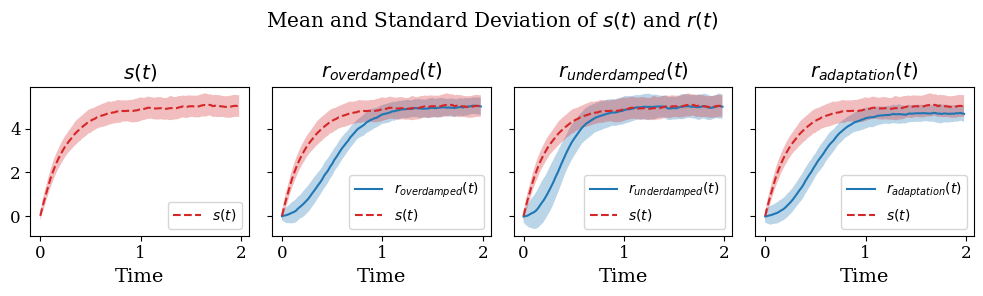

In [ ]:
#@title Plotting only the mean and standard deviation

fig, axs = plt.subplots(figsize=(10,3), nrows=1, ncols=4, sharex=True, sharey=True)
fig.suptitle('Mean and Standard Deviation of $s(t)$ and $r(t)$')

results = np.stack([s, r_1st_order, r_2nd_order, r_adaptation])
names   = [f'${string}(t)$' for string in ('s', 'r_{overdamped}', 'r_{underdamped}', 'r_{adaptation}')]

for i in range(4):
    axs[i].set(title=names[i])
    axs[i].set_xlabel('Time', fontsize=labelsize)

for i in range(4):
    if i > 0:
        mean, std = results[i].mean(0), results[i].std(axis=0)
        axs[i].plot(t_arr, mean, label=names[i])
        axs[i].fill_between(t_arr, mean-std, mean+std, alpha=0.3)
    mean, std = results[0].mean(0), results[0].std(axis=0)
    axs[i].plot(t_arr, results[0].mean(0), label=names[0], linestyle='--', c='C3')
    axs[i].fill_between(t_arr, mean-std, mean+std, alpha=0.3, facecolor='C3')
    axs[i].legend(loc='lower right', prop={'size': legendsize})

fig.tight_layout()

In [ ]:
#@title save the above curves as a csv
pd.DataFrame(
    np.vstack((np.arange(T)[None,:] * dt, results.mean(1), results.std(1))).T,
    columns=['time',
            'mean_s', 'mean_overdamped', 'mean_underdamped', 'mean_adaptation',
            'std_s',  'std_overdamped',  'std_underdamped',  'std_adaptation']
    ).to_csv('1d_ou.txt', index_label='idx')

In [ ]:
#@title RNN class
class RNN(nn.Module):
    def __init__(self, hidden_dim, std, act=nn.ReLU(), ln=False, seed=None):
        super().__init__()
        if seed is not None:
            torch.manual_seed(seed)
        self.W_in = nn.Linear(1, hidden_dim)
        self.W_rec = nn.Linear(hidden_dim, hidden_dim)
        self.W_out = nn.Linear(hidden_dim, 1)
        self.act = act
        self.std = std
        self.hidden_dim = hidden_dim
        self.ln = nn.LayerNorm(hidden_dim) if ln else None

    def forward(self, ds_dt, unmask_every=1):
        batch = ds_dt.shape[1]
        h = [torch.zeros(batch, self.hidden_dim)]
        for t in range(T-1):
            preact = self. W_in(ds_dt[t] * (t % unmask_every == 0)) + self.W_rec(h[t])
            if self.ln is not None:
                preact = self.ln(preact)
            h.append(self.act(
               preact + torch.randn(batch, self.hidden_dim) * self.std
            ))
        return self.W_out(torch.stack(h)) # T, N, 1

    def second_order(self, ds_dt, lambda_v=1, tau_a=20, b_a=0, unmask_every=1):
        batch = ds_dt.shape[1]
        h = [torch.zeros(batch, self.hidden_dim)]
        c = [torch.zeros(batch, self.hidden_dim)]
        v = [torch.zeros(batch, self.hidden_dim)]

        for t in range(T-1):
            preact = self. W_in(ds_dt[t] * (t % unmask_every == 0)) + self.W_rec(h[t])
            if self.ln is not None:
                preact = self.ln(preact)
            next_h = self.act(
               preact + torch.randn(batch, self.hidden_dim) * self.std
            )
            # second order stuff
            c.append(c[t] + (1/tau_a) * (-c[t] + b_a * h[t]))
            v.append((1 - lambda_v) * v[t] + (next_h - h[t]))
            h.append(h[t] - c[t] + v[-1])
        return self.W_out(torch.stack(h)) # T, N, 1


    def second_order_plaus(self, ds_dt, lambda_v1=1, lambda_v2=1, tau_a=20, b_a=0):
        batch = ds_dt.shape[1]
        h = [torch.zeros(batch, self.hidden_dim)]
        c = [torch.zeros(batch, self.hidden_dim)]

        for t in range(T-1):
            i = h[t]
            if t >= 1:
                i = h[t] + (1 - lambda_v1) * (h[t] - h[t-1])
            if t >= 2:
                i = h[t] + (1 - lambda_v2) * (h[t-1] - h[t-2])
            preact = self.W_in(ds_dt[t]) + self.W_rec(i)
            if self.ln is not None:
                preact = self.ln(preact)
            next_h = self.act(
               preact + torch.randn(batch, self.hidden_dim) * self.std
            )
            # second order stuff
            c.append(c[t] + (1/tau_a) * (-c[t] + b_a * h[t]))
            h.append(next_h - c[t])
        return self.W_out(torch.stack(h)) # T, N, 1

In [ ]:
#@title Training method

# make time the first dimension
S = torch.from_numpy(s).T.float()
dS = S.diff(axis=0)[...,None] # T, N, 1

def train(rnn, epochs=2_000, lr=1e-2, lambda_v=1, b_a=0, unmask_every=1):
    # optim
    optimizer = torch.optim.Adam(rnn.parameters(), lr=lr)

    for epoch in range(epochs+1):
        if lambda_v == 1 and b_a == 0:
            y = rnn(dS, unmask_every=unmask_every)
        else:
            y = rnn.second_order(dS, lambda_v=lambda_v, b_a=b_a)
        loss = (y.squeeze(-1) - S).square().mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if epoch % 100 == 0:
            print(f'Epoch {epoch}\tLoss:\t{loss.item()}')

In [ ]:
seed = 2

In [ ]:
#@title Train various nonlinear RNNs to path-integrate

hidden_dim = 10
std = 0.2
epochs = 2_000
lr = 1e-2

noisy_relu_rnn = RNN(hidden_dim=hidden_dim, std=std, seed=seed)
print("Training noisy ReLU RNN:")
train(noisy_relu_rnn, epochs=epochs, lr=lr)
#'''
noisy_tanh_rnn = RNN(hidden_dim=hidden_dim, std=std, seed=seed, act=nn.Tanh())
print("Training noisy tanh RNN:")
train(noisy_tanh_rnn, epochs=epochs, lr=lr)

noisy_ln_rnn = RNN(hidden_dim=hidden_dim, std=std, seed=seed, ln=True)
print("Training noisy LayerNorm + ReLU RNN:")
train(noisy_ln_rnn, epochs=epochs, lr=lr)#''';

Training noisy ReLU RNN:
Epoch 0	Loss:	25.61910057067871
Epoch 100	Loss:	0.6750363111495972
Epoch 200	Loss:	0.3528168201446533
Epoch 300	Loss:	0.28023335337638855
Epoch 400	Loss:	0.22802062332630157
Epoch 500	Loss:	0.8485061526298523
Epoch 600	Loss:	0.39846253395080566
Epoch 700	Loss:	0.2678154408931732
Epoch 800	Loss:	0.21069033443927765
Epoch 900	Loss:	0.7009924054145813
Epoch 1000	Loss:	0.2573338449001312
Epoch 1100	Loss:	0.205345019698143
Epoch 1200	Loss:	0.17836256325244904
Epoch 1300	Loss:	0.15288278460502625
Epoch 1400	Loss:	0.3068588972091675
Epoch 1500	Loss:	0.1786135733127594
Epoch 1600	Loss:	0.19369186460971832
Epoch 1700	Loss:	0.1281411349773407
Epoch 1800	Loss:	0.1740502268075943
Epoch 1900	Loss:	0.22275671362876892
Epoch 2000	Loss:	0.12047785520553589
Training noisy tanh RNN:
Epoch 0	Loss:	23.81971549987793
Epoch 100	Loss:	1.142922043800354
Epoch 200	Loss:	0.7111238241195679
Epoch 300	Loss:	0.36270907521247864
Epoch 400	Loss:	0.2899276614189148
Epoch 500	Loss:	0.258736908

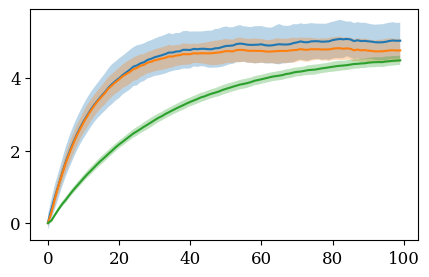

In [ ]:
#@title check
my_rnn = noisy_relu_rnn
y = my_rnn(dS).detach().squeeze(-1)
replay = my_rnn(dS*0).detach().squeeze(-1)

plt.figure(figsize=(5,3))
plt.plot(S.mean(1))
plt.fill_between(np.arange(T), S.mean(1)-S.std(1), S.mean(1)+S.std(1), alpha=0.3)
plt.plot(y.mean(1))
plt.fill_between(np.arange(T), y.mean(1)-y.std(1), y.mean(1)+y.std(1), alpha=0.3)
plt.plot(replay.mean(1))
plt.fill_between(np.arange(T), replay.mean(1)-replay.std(1), replay.mean(1)+replay.std(1), alpha=0.3)
plt.show()

In [ ]:
#@title Plotting function

def plot_row(axs_row, t, responses,
             titles=["$s(t)$", "$r_{overdamped}(t)$", "$r_{underdamped}(t)$", "$r_{adaptation}(t)$"]):
    for i in range(len(responses)):
        axs_row[i].set_title(titles[i])
        axs_row[i].set_xlabel('Time', fontsize=labelsize)
        # plot true distribution, time is first dimension
        mean, std = responses[0].mean(1), responses[0].std(1)
        axs_row[i].plot(t, mean, ls='--', c='C3')
        axs_row[i].fill_between(t, mean-std, mean+std, alpha=0.3, facecolor='C3')
        # plot synthesized distribution
        if i > 0:
            mean, std = responses[i].mean(1), responses[i].std(1)
            axs_row[i].plot(t, mean)
            axs_row[i].fill_between(t, mean-std, mean+std, alpha=0.3)

def plot_row_from_rnn(axs_row, t, rnn, lambda_v=0.7, b_a=0.01):
    plot_row(axs_row, t,
             responses=[
                 S, # true stimulus
                 rnn(dS*0).detach().squeeze(-1), # vanilla overdamped
                 rnn.second_order(dS*0, lambda_v=lambda_v).detach().squeeze(-1), # underdamped
                 rnn.second_order(dS*0, b_a=b_a).detach().squeeze(-1) # adaptation
             ])

def plot_underdamped_row_from_rnn(axs_row, t, rnn, lambda_v=0.7, lambda_v2=0.7):
    plot_row(
        axs_row, t,
        responses=[
            S, # true stimulus
            rnn(dS*0).detach().squeeze(-1), # vanilla overdamped
            rnn.second_order(dS*0, lambda_v=lambda_v).detach().squeeze(-1), # underdamped
            rnn.second_order_plaus(dS*0, lambda_v2=lambda_v2).detach().squeeze(-1) # plausible underdamped
        ],
        titles=["$s(t)$", "$r_{overdamped}(t)$", "$r_{underdamped}(t)$", "$r_{plaus. underdamped}(t)$"])

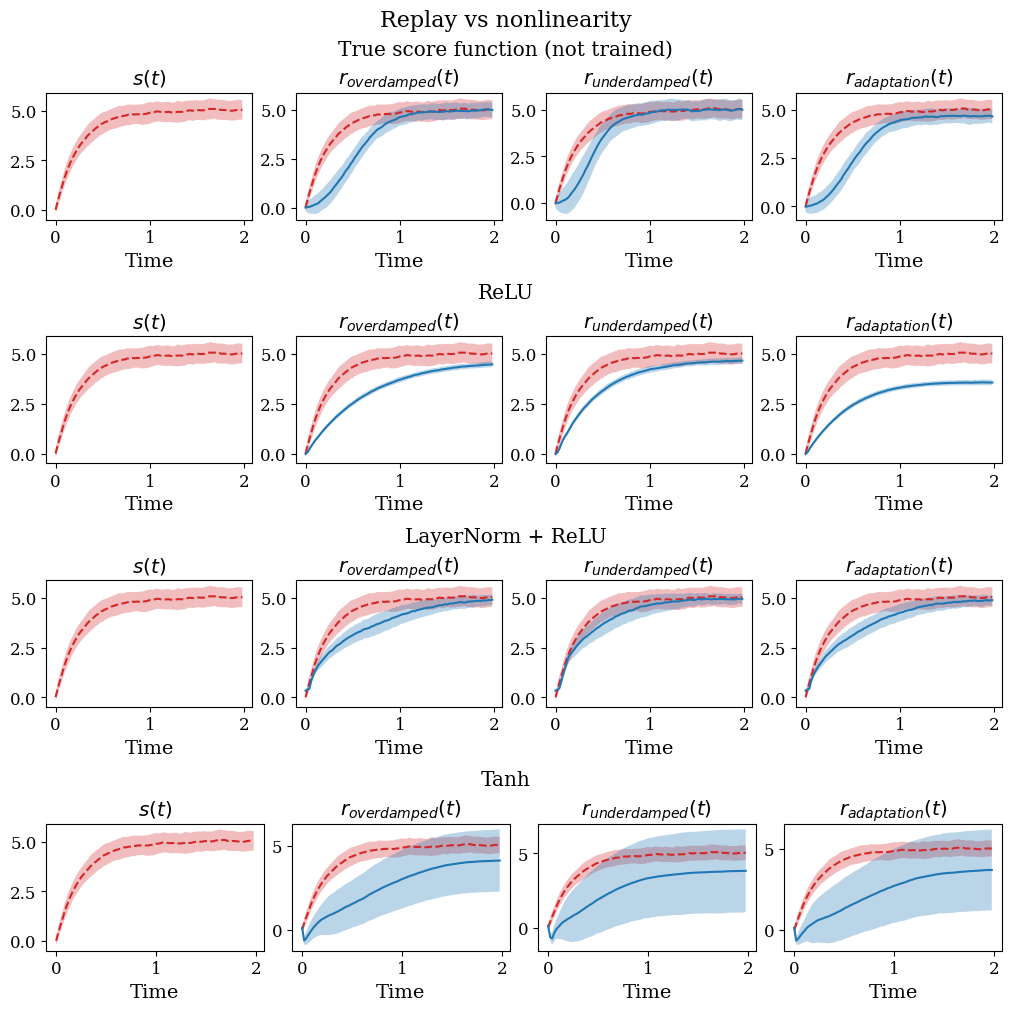

In [ ]:
#@title Various nonlinearities
fig = plt.figure(figsize=(10, 10), layout='constrained')
fig.suptitle('Replay vs nonlinearity', fontsize=16)
subfigs = fig.subfigures(nrows=4, ncols=1)

row_titles = ["True score function (not trained)", "ReLU", "LayerNorm + ReLU", "Tanh"]

# Iterate through subfigures
for row_index, subfig in enumerate(subfigs):
    # Set a suptitle for the current subfigure (this acts as the row title)
    subfig.suptitle(row_titles[row_index])#, fontsize=14,
    axs = subfig.subplots(nrows=1, ncols=4)
    if row_index == 0:
        plot_row(axs, t_arr, [s.T, r_1st_order.T, r_2nd_order.T, r_adaptation.T])
        continue

    plot_row_from_rnn(axs, t_arr, [None, noisy_relu_rnn, noisy_ln_rnn, noisy_tanh_rnn][row_index])

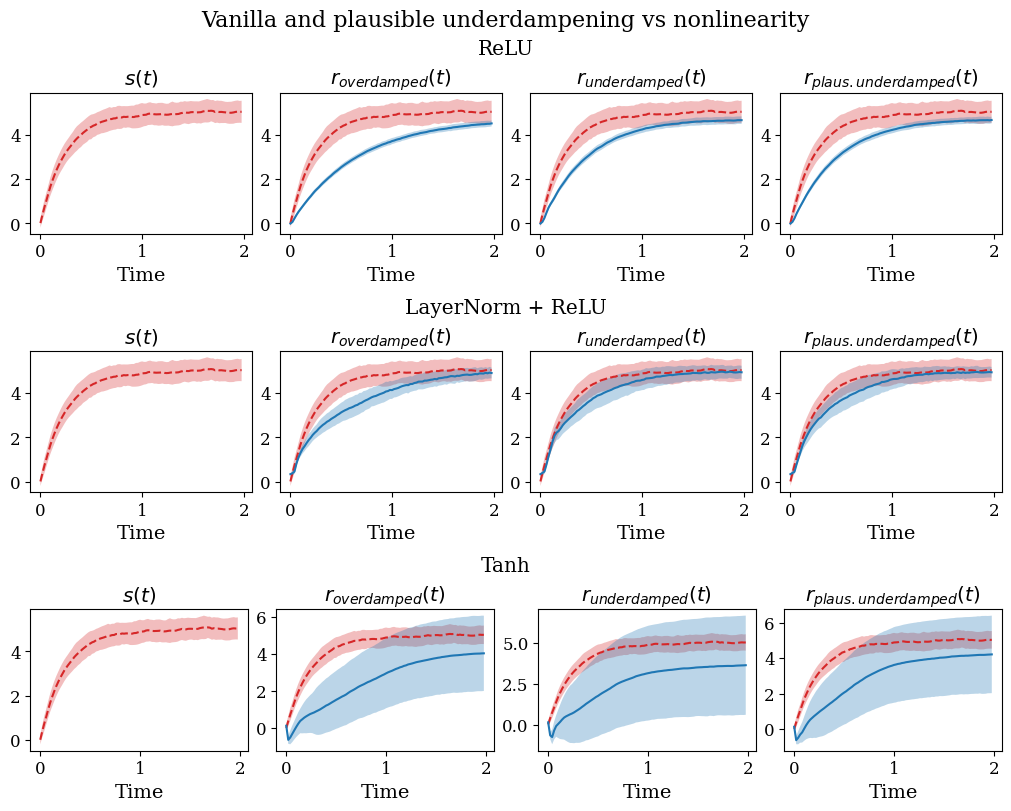

In [ ]:
#@title Plausible underdampening via adding velocity to inputs
fig = plt.figure(figsize=(10, 8), layout='constrained')
fig.suptitle('Vanilla and plausible underdampening vs nonlinearity', fontsize=16)
subfigs = fig.subfigures(nrows=3, ncols=1)

row_titles = ["ReLU", "LayerNorm + ReLU", "Tanh"]

# Iterate through subfigures
for row_index, subfig in enumerate(subfigs):
    # Set a suptitle for the current subfigure (this acts as the row title)
    subfig.suptitle(row_titles[row_index])#, fontsize=14,
    axs = subfig.subplots(nrows=1, ncols=4)
    plot_underdamped_row_from_rnn(
        axs, t_arr, [noisy_relu_rnn, noisy_ln_rnn, noisy_tanh_rnn][row_index],
        lambda_v=0.7,
        lambda_v2=0.7)

# other stuff

In [ ]:
#@title Train second-order RNNs to path-integrate
underdamped_rnn = RNN(hidden_dim=hidden_dim, std=std, seed=seed)
print("Training underdamped noisy ReLU RNN:")
train(underdamped_rnn, epochs=epochs, lr=lr, lambda_v=0.7)

adaptation_rnn = RNN(hidden_dim=hidden_dim, std=std, seed=seed)
print("Training adaptation noisy ReLU RNN:")
train(adaptation_rnn, epochs=epochs, lr=lr, b_a=0.01)

Training underdamped noisy ReLU RNN:
Epoch 0	Loss:	25.622196197509766
Epoch 100	Loss:	0.8720080256462097
Epoch 200	Loss:	0.6159471869468689
Epoch 300	Loss:	0.2974221408367157
Epoch 400	Loss:	0.4168592691421509
Epoch 500	Loss:	0.6301701664924622
Epoch 600	Loss:	0.35680079460144043
Epoch 700	Loss:	0.23965725302696228
Epoch 800	Loss:	3.334322690963745
Epoch 900	Loss:	1.1306105852127075
Epoch 1000	Loss:	0.9999672770500183
Epoch 1100	Loss:	0.8651941418647766
Epoch 1200	Loss:	0.6753565669059753
Epoch 1300	Loss:	0.41043272614479065
Epoch 1400	Loss:	0.26454776525497437
Epoch 1500	Loss:	0.21353313326835632
Epoch 1600	Loss:	0.1986916959285736
Epoch 1700	Loss:	0.2806803584098816
Epoch 1800	Loss:	12.873045921325684
Epoch 1900	Loss:	1.1004066467285156
Epoch 2000	Loss:	0.9176002740859985
Training adaptation noisy ReLU RNN:
Epoch 0	Loss:	25.614038467407227
Epoch 100	Loss:	0.7060612440109253
Epoch 200	Loss:	0.38505083322525024
Epoch 300	Loss:	0.2830878496170044
Epoch 400	Loss:	0.31081831455230713
Epoc

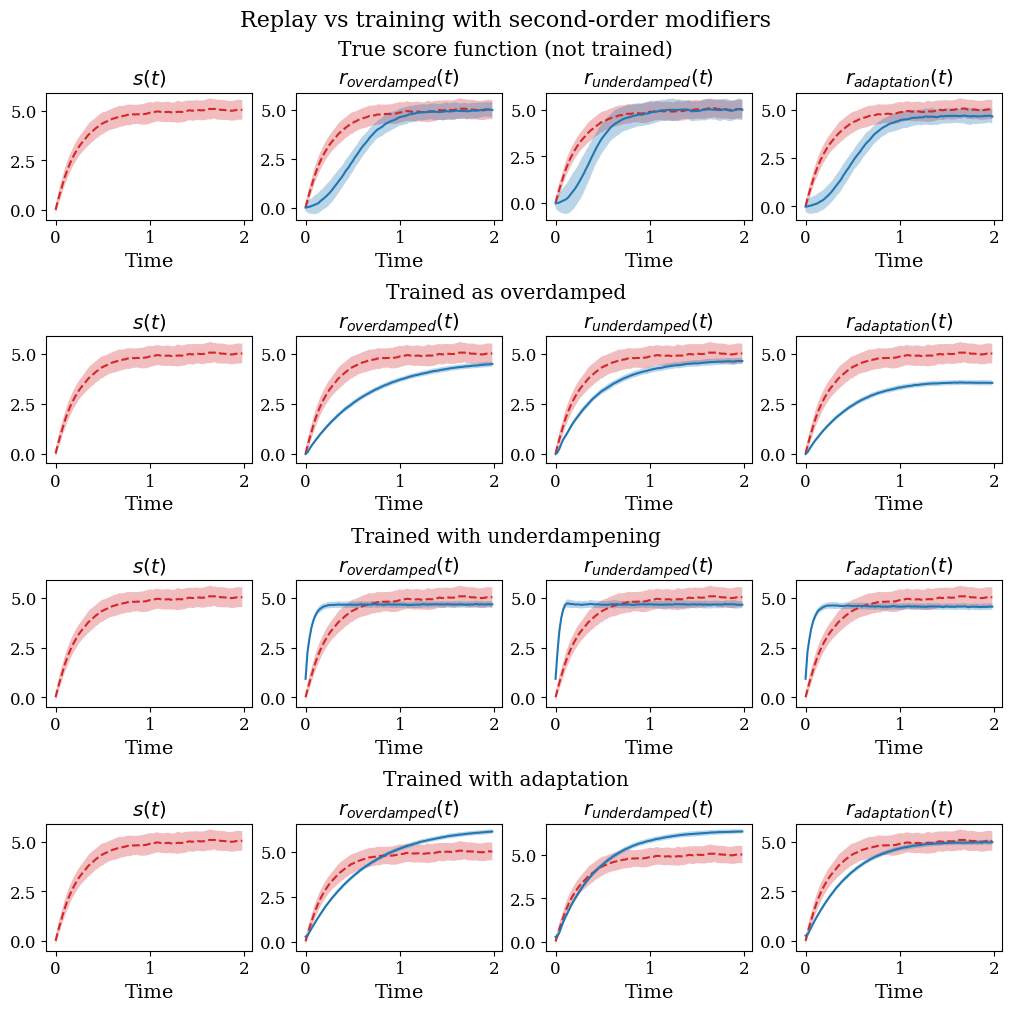

In [ ]:
#@title Overdamped-trained vs underdamped-trained vs adaptation-trained
fig = plt.figure(figsize=(10, 10), layout='constrained')
fig.suptitle('Replay vs training with second-order modifiers', fontsize=16)
subfigs = fig.subfigures(nrows=4, ncols=1)

row_titles = ["True score function (not trained)", "Trained as overdamped",
              "Trained with underdampening", "Trained with adaptation"]

# Iterate through subfigures
for row_index, subfig in enumerate(subfigs):
    # Set a suptitle for the current subfigure (this acts as the row title)
    subfig.suptitle(row_titles[row_index])#, fontsize=14
    axs = subfig.subplots(nrows=1, ncols=4)
    if row_index > 0:
        plot_row_from_rnn(axs, t_arr, [None, noisy_relu_rnn, underdamped_rnn, adaptation_rnn][row_index])
        continue

    plot_row(axs, t_arr, [s.T, r_1st_order.T, r_2nd_order.T, r_adaptation.T])

In [ ]:
#@title Train non-noisy (clean) RNN to path-integrate
clean_relu_rnn = RNN(hidden_dim=hidden_dim, std=0, seed=seed)
print("Training clean ReLU RNN:")
train(clean_relu_rnn, epochs=epochs, lr=lr)

Training clean ReLU RNN:
Epoch 0	Loss:	25.622243881225586
Epoch 100	Loss:	0.6213177442550659
Epoch 200	Loss:	0.3843940496444702
Epoch 300	Loss:	0.23103708028793335
Epoch 400	Loss:	0.8092447519302368
Epoch 500	Loss:	0.4462050199508667
Epoch 600	Loss:	0.2970017194747925
Epoch 700	Loss:	0.20130889117717743
Epoch 800	Loss:	0.14318817853927612
Epoch 900	Loss:	1.0664359331130981
Epoch 1000	Loss:	0.5799607634544373
Epoch 1100	Loss:	0.4002685844898224
Epoch 1200	Loss:	0.27003926038742065
Epoch 1300	Loss:	0.19670513272285461
Epoch 1400	Loss:	0.1511664092540741
Epoch 1500	Loss:	0.11574621498584747
Epoch 1600	Loss:	5.355843544006348
Epoch 1700	Loss:	1.0315463542938232
Epoch 1800	Loss:	0.9793416857719421
Epoch 1900	Loss:	0.7616276144981384
Epoch 2000	Loss:	0.4736085832118988


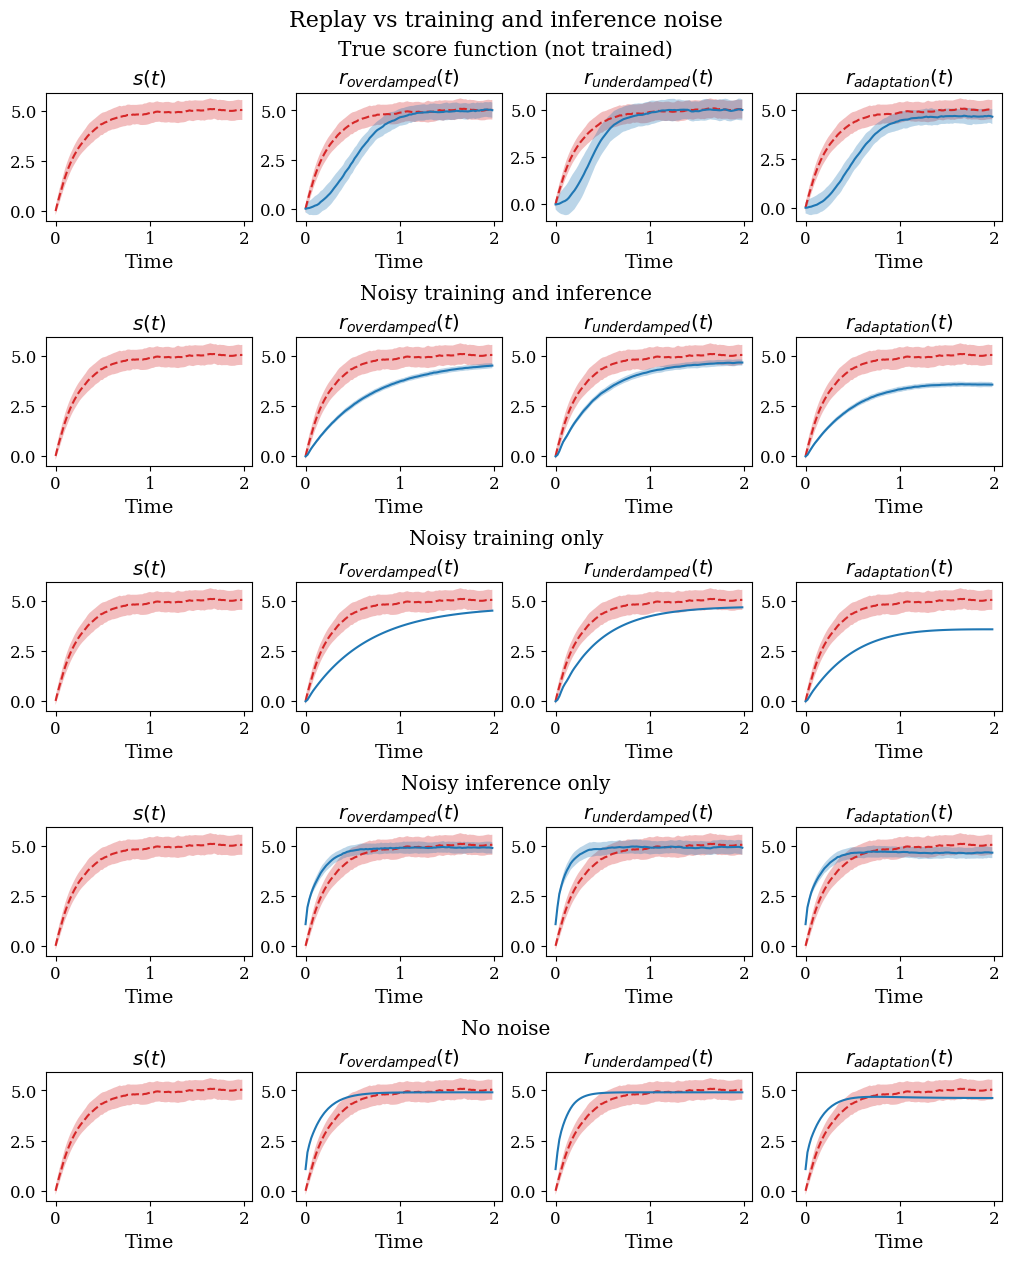

In [ ]:
#@title Noise vs no noise
fig = plt.figure(figsize=(10, 12.5), layout='constrained')
fig.suptitle('Replay vs training and inference noise', fontsize=16)
subfigs = fig.subfigures(nrows=5, ncols=1)

row_titles = ["True score function (not trained)", "Noisy training and inference",
              "Noisy training only", "Noisy inference only", "No noise"]

# Iterate through subfigures
for row_index, subfig in enumerate(subfigs):
    # Set a suptitle for the current subfigure (this acts as the row title)
    subfig.suptitle(row_titles[row_index])#, fontsize=14
    axs = subfig.subplots(nrows=1, ncols=4)
    if row_index > 0:
        my_rnn = [noisy_relu_rnn, clean_relu_rnn][(row_index - 1) // 2]
        my_rnn.std = [std, 0][(row_index - 1) % 2]
        plot_row_from_rnn(axs, t_arr, my_rnn)
        my_rnn.std = std
        continue

    plot_row(axs, t_arr, [s.T, r_1st_order.T, r_2nd_order.T, r_adaptation.T])